Hotel Cancellation 

In [1]:
import pandas as pd
import numpy as np
import mlba
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_curve, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

### Retrieving data set from github repository

In [2]:
url = 'https://raw.githubusercontent.com/sascott9655/ADS-505-Hotel_Bookings_Project/main/hotel_bookings.csv'
df = pd.read_csv(url)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,no,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
1,Resort Hotel,no,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
2,Resort Hotel,no,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
3,Resort Hotel,no,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
4,Resort Hotel,no,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,7/3/2015


### Sanity Check

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  object 
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [4]:
df["is_canceled"] = (df["is_canceled"] == "yes").astype(int) # yes/no -> 1/0 (this will matter for modeling later on!)
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("\nMissing values:")
print(pd.DataFrame({"count": missing, "percent": (missing / len(df) * 100).round(1)}))
df.describe().T.round(2)


Missing values:
           count  percent
company   112593     94.3
agent      16340     13.7
country      488      0.4
children       4      0.0


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


In [5]:
#children impute missing value with zero(since they are so few missing values and most of the data shows that customers are not children 
#and/or with children)
impute_with_zero = (df['children'].isna() == True)
impute_with_zero = impute_with_zero[impute_with_zero == True]
df.loc[impute_with_zero.index, 'children'] = 0
df['children'].isna().sum()
 
df['country'] = df['country'].fillna('Unknown') #fill it with unknown as it shouldn't impact the data too much
df['country'].isna().sum()

df["has_company"] = df["company"].notna().astype(int)
df["has_company"]

df["has_agent"] = df["agent"].notna().astype(int) 
df["has_agent"]

df = df.drop(columns=["agent", "company"])

In [6]:
df.isna().sum() #no more missing data!!!

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests   

In [7]:
df = df[(df["adults"] + df["children"] + df["babies"]) > 0] #gets rid of rows where there was no people tracked

In [8]:
# Was there a deposit for the booking? If so, what kind?
df['deposit_type'].value_counts().to_frame()

,count
deposit_type,
No Deposit,104461
Non Refund,14587
Refundable,162


### Visualizations

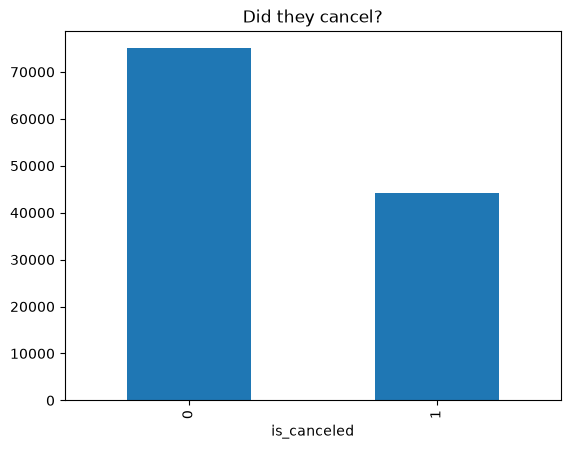

In [9]:
df['is_canceled'].value_counts().plot(kind='bar', title='Did they cancel?')
plt.show()

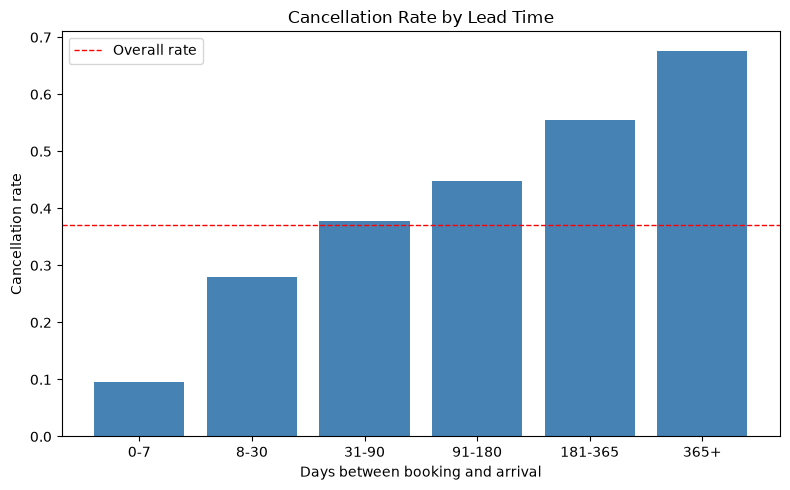

           count  cancel_rate
lead_time                    
0-7        19635        0.096
8-30       18945        0.279
31-90      29529        0.377
91-180     26420        0.447
181-365    21534        0.555
365+        3147        0.677


In [10]:
#Nice visual to show likelihood of cancellation based on how many days passed by.
lead_bins = pd.cut(df["lead_time"], bins=[-1, 7, 30, 90, 180, 365, 800],
                  labels=["0-7", "8-30", "31-90", "91-180", "181-365","365+"])
lead_rates = df.groupby(lead_bins, observed=True)["is_canceled"].agg(count="size", cancel_rate="mean")
plt.figure(figsize=(8, 5))
plt.bar(lead_rates.index.astype(str), lead_rates["cancel_rate"], color="steelblue")
plt.axhline(df["is_canceled"].mean(), color="red", linestyle="--", linewidth=1,label="Overall rate")
plt.title("Cancellation Rate by Lead Time")
plt.xlabel("Days between booking and arrival")
plt.ylabel("Cancellation rate")
plt.legend()
plt.tight_layout()
plt.show()
print(lead_rates.round(3))

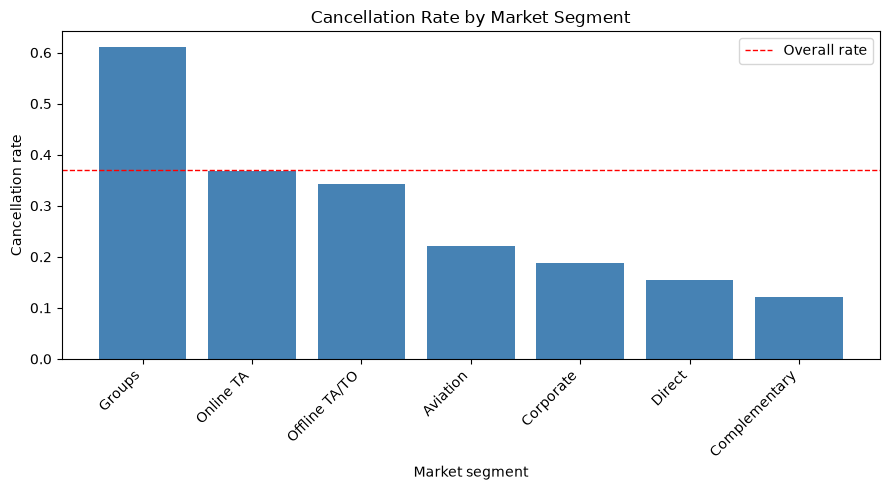

                count  cancel_rate
market_segment                    
Groups          19791        0.611
Online TA       56408        0.368
Offline TA/TO   24182        0.343
Aviation          235        0.221
Corporate        5282        0.188
Direct          12582        0.154
Complementary     728        0.122


In [11]:
seg_rates = (df.groupby("market_segment")["is_canceled"].agg(count="size",
            cancel_rate="mean").query("count > 100").sort_values("cancel_rate", ascending=False)) 
plt.figure(figsize=(9, 5))
plt.bar(seg_rates.index, seg_rates["cancel_rate"], color="steelblue")
plt.axhline(df["is_canceled"].mean(), color="red", linestyle="--", linewidth=1,label="Overall rate")
plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Market segment")
plt.ylabel("Cancellation rate")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()
print(seg_rates.round(3))

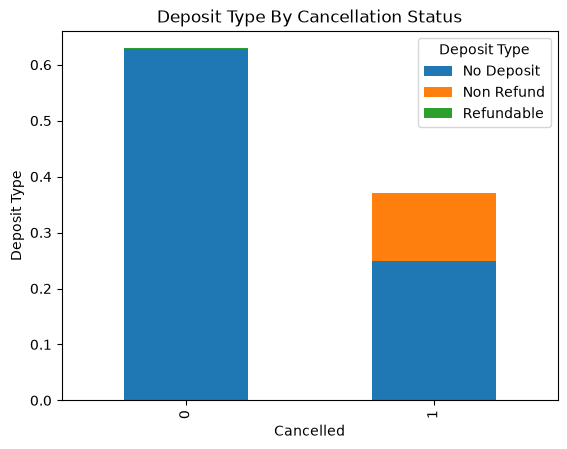

In [12]:
pd.crosstab(df['is_canceled'], df['deposit_type'], normalize=True).plot(kind='bar', stacked=True)
plt.title('Deposit Type By Cancellation Status')
plt.xlabel('Cancelled')
plt.ylabel('Deposit Type')
plt.legend(title='Deposit Type')
plt.show()

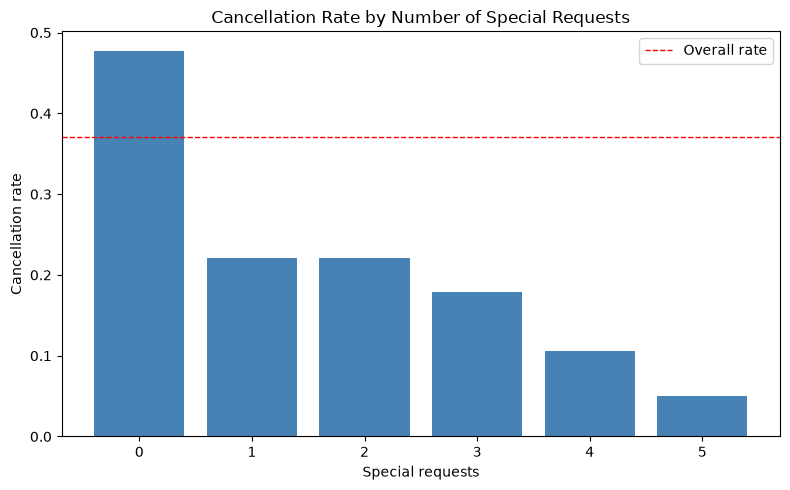

                           count  cancel_rate
total_of_special_requests                    
0                          70201        0.478
1                          33183        0.220
2                          12952        0.221
3                           2494        0.178
4                            340        0.106
5                             40        0.050


In [13]:
req_rates = df.groupby("total_of_special_requests")["is_canceled"].agg(count="size", cancel_rate="mean")
plt.figure(figsize=(8, 5))
plt.bar(req_rates.index.astype(str), req_rates["cancel_rate"],color="steelblue")
plt.axhline(df["is_canceled"].mean(), color="red", linestyle="--", linewidth=1,label="Overall rate")
plt.title("Cancellation Rate by Number of Special Requests")
plt.xlabel("Special requests")
plt.ylabel("Cancellation rate")
plt.legend()
plt.tight_layout()
plt.show()
print(req_rates.round(3))

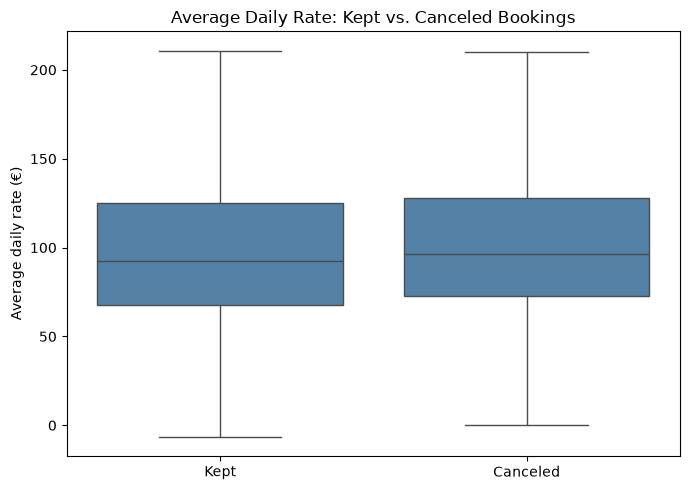

               mean   50%
is_canceled              
0            100.17  92.7
1            105.02  96.3


In [14]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="is_canceled", y="adr", showfliers=False,color="steelblue")
plt.xticks([0, 1], ["Kept", "Canceled"])
plt.title("Average Daily Rate: Kept vs. Canceled Bookings")
plt.xlabel("")
plt.ylabel("Average daily rate (€)")
plt.tight_layout()
plt.show()
print(df.groupby("is_canceled")["adr"].describe()[["mean", "50%"]].round(2))

### Feature Engineering

In [15]:
#dropping these two columns as the information they provide
#does not seem significant enough considering we have
#arrival_date_year and arrival_date_month
#dropping reservation_status and reservation_status_date because both of these columns allude to directly
#predicting the target variable is_canceled which we do not want a model with strong features that tell us
#the outcome based on these two features alone (not helpful for the business to improve hotel cancellation rate)
df = df.drop(columns=['arrival_date_week_number','arrival_date_day_of_month', 'assigned_room_type',
                     'reservation_status','reservation_status_date'])

In [16]:
df['length_of_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df[['stays_in_weekend_nights', 'stays_in_week_nights', 'length_of_stay']].head(30)
df.drop(columns=['stays_in_weekend_nights', 'stays_in_week_nights'])

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,adults,children,babies,meal,country,...,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,has_company,has_agent,length_of_stay
0,Resort Hotel,0,342,2015,July,2,0.0,0,BB,PRT,...,3,No Deposit,0,Transient,0.00,0,0,0,0,0
1,Resort Hotel,0,737,2015,July,2,0.0,0,BB,PRT,...,4,No Deposit,0,Transient,0.00,0,0,0,0,0
2,Resort Hotel,0,7,2015,July,1,0.0,0,BB,GBR,...,0,No Deposit,0,Transient,75.00,0,0,0,0,1
3,Resort Hotel,0,13,2015,July,1,0.0,0,BB,GBR,...,0,No Deposit,0,Transient,75.00,0,0,0,1,1
4,Resort Hotel,0,14,2015,July,2,0.0,0,BB,GBR,...,0,No Deposit,0,Transient,98.00,0,1,0,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,2,0.0,0,BB,BEL,...,0,No Deposit,0,Transient,96.14,0,0,0,1,7
119386,City Hotel,0,102,2017,August,3,0.0,0,BB,FRA,...,0,No Deposit,0,Transient,225.43,0,2,0,1,7
119387,City Hotel,0,34,2017,August,2,0.0,0,BB,DEU,...,0,No Deposit,0,Transient,157.71,0,4,0,1,7
119388,City Hotel,0,109,2017,August,2,0.0,0,BB,GBR,...,0,No Deposit,0,Transient,104.40,0,0,0,1,7


In [17]:
#for features stays_in_weekend_nights and stays_in_week_nights we can feature engineer these two columns into 
#one where it is a binary feature on whether they stay the weekend or not
df['stays_in_weekend_nights'].value_counts()
weekend_nights_yes = df['stays_in_weekend_nights'] > 0
weekend_nights_yes = weekend_nights_yes[weekend_nights_yes == True]
df.loc[weekend_nights_yes.index, 'stays_in_weekend_nights'] = 1
df['stays_in_weekend_nights'].value_counts()

#drop stay_in_week_nights column as it is no longer needed
df = df.drop(columns=['stays_in_week_nights'])

In [18]:
#for features children and babies consider combining them into one group since individual they act the same
#(running this code multiple times will change results
df['children'] = df['children'] + df['babies']
df['children'] = df['children'].astype('int')

df = df.drop(columns=['babies'])

In [19]:
top_countries = df["country"].value_counts().nlargest(10).index
#I like the idea of having an other column for countries that do not appear in the data set often
df["country"] = df["country"].where(df["country"].isin(top_countries), "Other")

Columns like meal, country, reserved_room_type, customer_type, deposit_type  need to be one hot-encoded!

In [20]:
#Need to prevent data leakage so I decided to encode my variables in the training data only


#leave hotel variable out because we will split the data on it
cat_cols = ['hotel','arrival_date_month', 'meal', 'country', 'reserved_room_type', 'customer_type','deposit_type']
df.info()
num_cols = ['lead_time', 'arrival_date_year', 'adults', 'children', 'previous_cancellations', 'previous_bookings_not_canceled']

#for cty and hotel model
cat_cols2 = ['arrival_date_month', 'meal', 'country', 'reserved_room_type', 'customer_type','deposit_type']

<class 'pandas.core.frame.DataFrame'>
Index: 119210 entries, 0 to 119389
Data columns (total 26 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119210 non-null  object 
 1   is_canceled                     119210 non-null  int64  
 2   lead_time                       119210 non-null  int64  
 3   arrival_date_year               119210 non-null  int64  
 4   arrival_date_month              119210 non-null  object 
 5   stays_in_weekend_nights         119210 non-null  int64  
 6   adults                          119210 non-null  int64  
 7   children                        119210 non-null  int64  
 8   meal                            119210 non-null  object 
 9   country                         119210 non-null  object 
 10  market_segment                  119210 non-null  object 
 11  distribution_channel            119210 non-null  object 
 12  is_repeated_guest    

In [21]:
#help set up what to train/test split the data on. 
city_hotel = df[df["hotel"] == "City Hotel"].copy()
resort_hotel = df[df["hotel"] == "Resort Hotel"].copy()
print(city_hotel["is_canceled"].mean()) 
print(resort_hotel["is_canceled"].mean())

0.4178593534858457
0.27767373336329815


In [22]:
city_hotel = city_hotel.drop(columns=['hotel'])
city_hotel.columns

resort_hotel = resort_hotel.drop(columns=['hotel'])
resort_hotel.columns

Index(['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month',
       'stays_in_weekend_nights', 'adults', 'children', 'meal', 'country',
       'market_segment', 'distribution_channel', 'is_repeated_guest',
       'previous_cancellations', 'previous_bookings_not_canceled',
       'reserved_room_type', 'booking_changes', 'deposit_type',
       'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'has_company', 'has_agent', 'length_of_stay'],
      dtype='object')

City hotel a little more likely to be canceled than resort hotel. 

In [23]:
df.shape

(119210, 26)

In [24]:
outcome = 'is_canceled'
predictors = df.drop(columns=['is_canceled'])
predictors = predictors.columns

In [25]:
#create 3 neural nets all (with grid search)
#1. base neural net
#2. resort neural net
#3. city_hotel neural net

In [26]:
preprocessing = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("numerical", StandardScaler(), num_cols)
])

preprocessing2 = ColumnTransformer([ #for the resort and cty hotel models
    ("categorical", OneHotEncoder(handle_unknown="ignore"), cat_cols2),
    ("numerical", StandardScaler(), num_cols)
])

In [27]:
outcome = "is_canceled"
X = df.drop(columns=[outcome])
y = df[outcome]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

In [28]:
#Create the split and have all 3 models share the same train_test_split

#City Hotel
city_train_mask = X_train["hotel"] == "City Hotel"
city_test_mask = X_test["hotel"] == "City Hotel"

X_city_train = X_train.loc[city_train_mask].drop(columns=["hotel"])
y_city_train = y_train.loc[city_train_mask]

X_city_test = X_test.loc[city_test_mask].drop(columns=["hotel"])
y_city_test = y_test.loc[city_test_mask]


# Resort Hotel
resort_train_mask = X_train["hotel"] == "Resort Hotel"
resort_test_mask = X_test["hotel"] == "Resort Hotel"

X_resort_train = X_train.loc[resort_train_mask].drop(columns=["hotel"])
y_resort_train = y_train.loc[resort_train_mask]

X_resort_test = X_test.loc[resort_test_mask].drop(columns=["hotel"])
y_resort_test = y_test.loc[resort_test_mask]

In [29]:
base_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("base_net", MLPClassifier(random_state=1, max_iter=300))
])

#Grid search 
#the model name is required in front of the of the paramgrid variable so the pipeline knows the model 
base_param_grid =  {
    'base_net__hidden_layer_sizes': [(5,), (10,), (20,)], 
    'base_net__activation': ["tanh", "relu"],
    'base_net__solver': ["adam", "sgd"]
}

base_net = GridSearchCV(base_pipeline, base_param_grid, cv=5, n_jobs=-1)
base_net.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'base_net__activation': ['tanh', 'relu'], 'base_net__hidden_layer_sizes': [(5,), (10,), ...], 'base_net__solver': ['adam', 'sgd']}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True


In [30]:
city_hotel_pipeline = Pipeline([
    ("preprocessing", preprocessing2),
    ("city_hotel_net", MLPClassifier(random_state=1, max_iter=300))
])

city_param_grid =  {
    'city_hotel_net__hidden_layer_sizes': [(5,), (10,), (20,)], 
    'city_hotel_net__activation': ["tanh", "relu"],
    'city_hotel_net__solver': ["adam","sgd"]
}

city_hotel_net = GridSearchCV(city_hotel_pipeline, city_param_grid, cv=5, n_jobs=-1)
city_hotel_net.fit(X_city_train, y_city_train)
city_hotel_net

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'city_hotel_net__activation': ['tanh', 'relu'], 'city_hotel_net__hidden_layer_sizes': [(5,), (10,), ...], 'city_hotel_net__solver': ['adam', 'sgd']}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for call

In [31]:
resort_hotel_pipeline = Pipeline([
    ("preprocessing", preprocessing2),
    ("resort_hotel_net", MLPClassifier(random_state=1, max_iter=300))
])

resort_param_grid =  {
    'resort_hotel_net__hidden_layer_sizes': [(5,), (10,), (20,)], 
    'resort_hotel_net__activation': ["tanh", "relu"],
    'resort_hotel_net__solver': ["adam", "sgd"]
}

resort_hotel_net = GridSearchCV(resort_hotel_pipeline, resort_param_grid, cv=5, n_jobs=-1)
resort_hotel_net.fit(X_resort_train, y_resort_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'resort_hotel_net__activation': ['tanh', 'relu'], 'resort_hotel_net__hidden_layer_sizes': [(5,), (10,), ...], 'resort_hotel_net__solver': ['adam', 'sgd']}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support fo

### Model Evaluation

In [32]:
print(base_net.best_params_)
print(city_hotel_net.best_params_)
print(resort_hotel_net.best_params_)

{'base_net__activation': 'tanh', 'base_net__hidden_layer_sizes': (20,), 'base_net__solver': 'adam'}
{'city_hotel_net__activation': 'relu', 'city_hotel_net__hidden_layer_sizes': (20,), 'city_hotel_net__solver': 'adam'}
{'resort_hotel_net__activation': 'relu', 'resort_hotel_net__hidden_layer_sizes': (20,), 'resort_hotel_net__solver': 'adam'}


In [33]:
base_net_pred = base_net.predict(X_test)
cm_base = confusion_matrix(y_test, base_net_pred)
cm_base

array([[20377,  2126],
       [ 4813,  8447]])

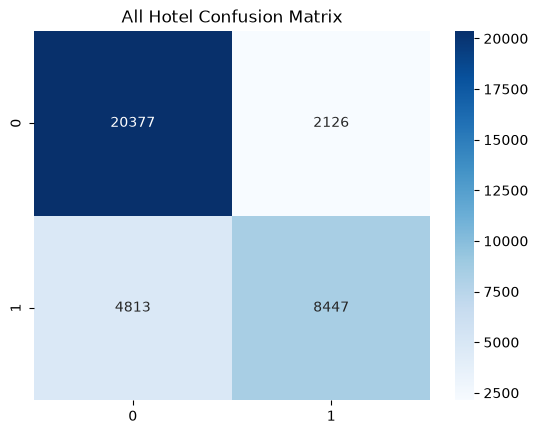

In [34]:
sns.heatmap(cm_base, cmap="Blues", annot=True, fmt="d")
plt.title("All Hotel Confusion Matrix")
plt.show()

In [35]:
city_hotel_pred = city_hotel_net.predict(X_city_test)
cm_city = confusion_matrix(y_city_test, city_hotel_pred)
cm_city

array([[12487,  1357],
       [ 3627,  6327]])

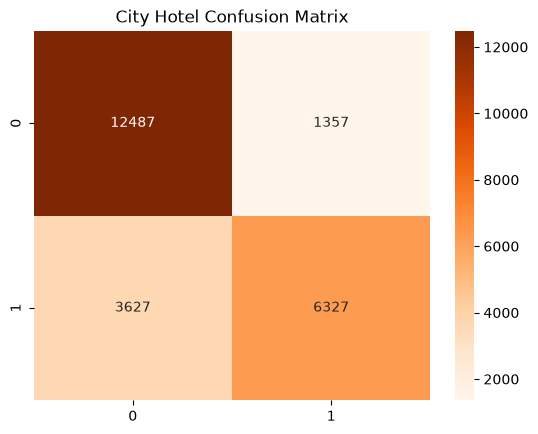

In [36]:
sns.heatmap(cm_city, cmap="Oranges", annot=True, fmt="d")
plt.title("City Hotel Confusion Matrix")
plt.show()

In [37]:
resort_hotel_pred = resort_hotel_net.predict(X_resort_test)
cm_resort = confusion_matrix(y_resort_test, resort_hotel_pred)
cm_resort

array([[7835,  824],
       [1170, 2136]])

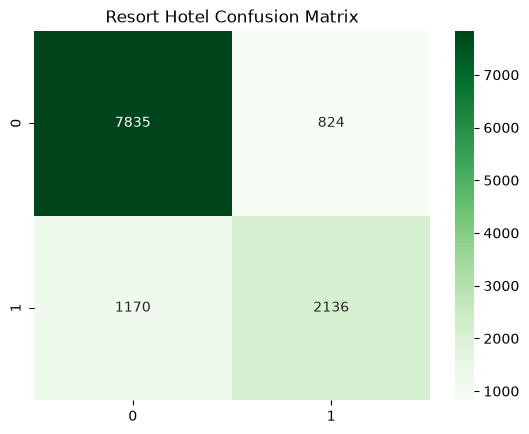

In [38]:
sns.heatmap(cm_resort, cmap="Greens", annot=True, fmt="d")
plt.title("Resort Hotel Confusion Matrix")
plt.show()

In [39]:
base_accuracy_score = accuracy_score(y_test, base_net_pred)
base_precision_score = precision_score(y_test, base_net_pred)
base_recall_score = recall_score(y_test, base_net_pred)
base_f1_score = f1_score(y_test, base_net_pred)

base_results = pd.DataFrame({'Accuracy score' : base_accuracy_score,
                        'Precision score' : base_precision_score,
                        'Recall score' : base_recall_score,
                        'F1-Score' : base_f1_score
                        }, index=["Base Model"])

city_hotel_accuracy_score = accuracy_score(y_city_test, city_hotel_pred)
city_hotel_precision_score = precision_score(y_city_test, city_hotel_pred)
city_hotel_recall_score = recall_score(y_city_test, city_hotel_pred)
city_hotel_f1_score = f1_score(y_city_test, city_hotel_pred)

city_hotel_results = pd.DataFrame({'Accuracy score' : city_hotel_accuracy_score,
                        'Precision score' : city_hotel_precision_score,
                        'Recall score' : city_hotel_recall_score,
                        'F1-Score' : city_hotel_f1_score
                        }, index=["City Hotel Model"])

resort_hotel_accuracy_score = accuracy_score(y_resort_test, resort_hotel_pred)
resort_hotel_precision_score = precision_score(y_resort_test, resort_hotel_pred)
resort_hotel_recall_score = recall_score(y_resort_test, resort_hotel_pred)
resort_hotel_f1_score = f1_score(y_resort_test, resort_hotel_pred)

resort_hotel_results = pd.DataFrame({'Accuracy score' : resort_hotel_accuracy_score,
                        'Precision score' : resort_hotel_precision_score,
                        'Recall score' : resort_hotel_recall_score,
                        'F1-Score' : resort_hotel_f1_score
                        }, index=["Resort Hotel Model"])

base_results

,Accuracy score,Precision score,Recall score,F1-Score
Base Model,0.805973,0.798922,0.637029,0.708849


In [40]:
city_hotel_results

,Accuracy score,Precision score,Recall score,F1-Score
City Hotel Model,0.790571,0.823399,0.635624,0.717428


In [41]:
resort_hotel_results

,Accuracy score,Precision score,Recall score,F1-Score
Resort Hotel Model,0.833347,0.721622,0.646098,0.681775


Analysis: The neural network models performed well on understanding and predicting hotel cancellations. The Resort's Hotel Neural Network accurately predicted cancellations best with 0.83 certainty, meaning it correctly classified approximately 83% of observations in its evaluation dataset. The city hotel model has the highest precision score of 0.82 meaning it would predict and classify a canceled hotel observation better than the other two models. The Resort model which contains all observations had the highest recall score of 0.64 which shows that it identified a greater proportion of actual cancellations than the other models.  

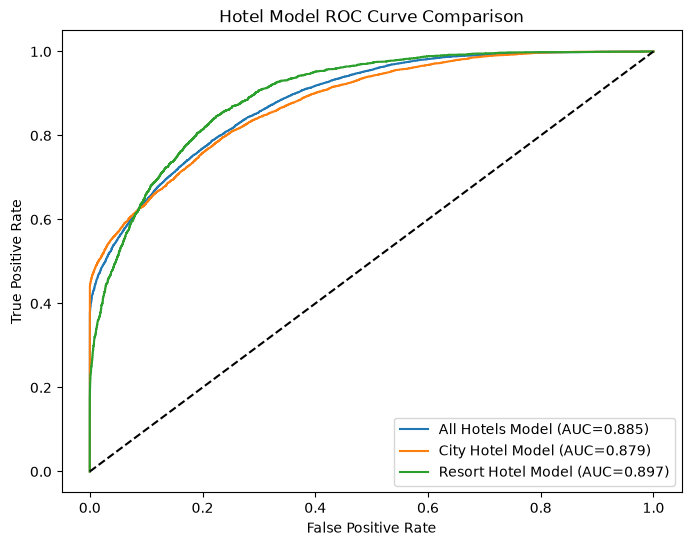

In [42]:
models = {"All Hotels Model": (base_net, X_test, y_test),
          "City Hotel Model": (city_hotel_net, X_city_test, y_city_test),
         "Resort Hotel Model": (resort_hotel_net, X_resort_test, y_resort_test)
}

plt.figure(figsize=(8,6))
for name, (model, X, y) in models.items():
    proba = model.predict_proba(X)[:,1]
    fpr, tpr, _ = roc_curve(y, proba) #false positive rate and true positive rate
    auc = roc_auc_score(y, proba)
    plt.plot( fpr,tpr,label=f"{name} (AUC={auc:.3f})")

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Hotel Model ROC Curve Comparison")
plt.legend()
plt.show()

Analysis: This graph shows the risk of using each model and how well each model performs. Places where the line touch closer to the upper left corner of the graph are optimally what a perfect model would look like. The closer to the left side the more we minimize overbooking, so those customers do not stay at another place. The right side of the graph shows a higher risk, higher reward approach, where hotel rooms that are believe to be canceled based on these models, can be resold to maximize occupancy and revenue, but risk overbooking. The Resort Hotel Model has the highest AUC Area Under Curve score which shows that this model has the best understanding of knowing when a hotel cancellation will occur, however it is also the model with the lowest amount of observation data. The Resort Hotel curve also shows that if the business went with the risk-averse approach, it would be the model for the business to use. However if we went for the more revenue aggressive approach the city hotel model would be better. All models were tested on the same test data to interpret results.  

In [43]:
resale_room_prob = 0.60 #probability of reselling room (number is hypothetical and not from actual dataset)
recovered_percentage = 1.00  #fraction of room revenue recovered when resold
cost = 10 #cost of flagged booking



In [44]:
#Estimated probabilities of canceled trip
cancel_probability = base_net.predict_proba(X_test)[:, 1]

#Create data table out of the X_test
base_eval_table = X_test.copy()

base_eval_table["actual_canceled"] = y_test
base_eval_table["cancel_probability"] = cancel_probability
base_eval_table["predicted_canceled"] = base_net.predict(X_test)

#Amount the customers pays for their stay
base_eval_table["room_revenue"] = (
    X_test["adr"] * X_test['length_of_stay']
)
base_eval_table["room_revenue"]

base_eval_table["expected_recovery"] = (base_eval_table["cancel_probability"] * base_eval_table["room_revenue"] * resale_room_prob * recovered_percentage)
base_eval_table["expected_net_value"] = (base_eval_table["expected_recovery"] - cost)

In [45]:
#Estimated probabilities of canceled trip
cancel_probability2 = city_hotel_net.predict_proba(X_city_test)[:, 1]

#Create data table out of the X_test
city_hotel_eval_table = X_city_test.copy()

city_hotel_eval_table["actual_canceled"] = y_city_test
city_hotel_eval_table["cancel_probability"] = cancel_probability2
city_hotel_eval_table["predicted_canceled"] = city_hotel_net.predict(X_city_test)

#Amount the customers pays for their stay
city_hotel_eval_table["room_revenue"] = (
    X_city_test["adr"] * X_city_test['length_of_stay']
)
city_hotel_eval_table["room_revenue"]

city_hotel_eval_table["expected_recovery"] = (city_hotel_eval_table["cancel_probability"] * city_hotel_eval_table["room_revenue"] * resale_room_prob * recovered_percentage)
city_hotel_eval_table["expected_net_value"] = (city_hotel_eval_table["expected_recovery"] - cost)

In [46]:
cancel_probability3 = resort_hotel_net.predict_proba(X_resort_test)[:, 1]

#Create data table out of the X_test
resort_hotel_eval_table = X_resort_test.copy()

resort_hotel_eval_table["actual_canceled"] = y_resort_test
resort_hotel_eval_table["cancel_probability"] = cancel_probability3
resort_hotel_eval_table["predicted_canceled"] = resort_hotel_net.predict(X_resort_test)

#Amount the customers pays for their stay
resort_hotel_eval_table["room_revenue"] = X_resort_test["adr"] * X_resort_test['length_of_stay']
resort_hotel_eval_table["room_revenue"]

resort_hotel_eval_table["expected_recovery"] = resort_hotel_eval_table["cancel_probability"] * resort_hotel_eval_table["room_revenue"] * resale_room_prob * recovered_percentage
resort_hotel_eval_table["expected_net_value"] = resort_hotel_eval_table["expected_recovery"] - cost

In [47]:
#Had AI assist in helping combine the tables and thresholds

thresholds = [0.40, 0.50, 0.60]

# Combine the two hotel-specific evaluation tables because they different patterns that influence whether a booking gets canceled.
separate_eval_table = pd.concat([
    city_hotel_eval_table,
    resort_hotel_eval_table
]).sort_index()

def compare_strategy(table, strategy_name):
    results = []

    actual = table["actual_canceled"].to_numpy()
    probabilities = table["cancel_probability"].to_numpy()

    for threshold in thresholds:
        # Flag bookings whose cancellation probability meets the threshold
        flagged = probabilities >= threshold

        # Financial calculations apply only to flagged bookings
        expected_recovery = table.loc[flagged, "expected_recovery"].sum()
        action_cost = flagged.sum() * cost
        net_value = expected_recovery - action_cost

        results.append({
            "Strategy": strategy_name,
            "Threshold": threshold,
            "Bookings Flagged": int(flagged.sum()),
            "Accuracy": accuracy_score(actual, flagged),
            "Precision": precision_score(actual, flagged, zero_division=0),
            "Recall": recall_score(actual, flagged, zero_division=0),
            "Expected Recovery": expected_recovery,
            "Action Cost": action_cost,
            "Net Expected Value": net_value
        })

    return results


comparison = pd.DataFrame(
    compare_strategy(base_eval_table, "Base Model")
    + compare_strategy(separate_eval_table, "Separate Hotel Models")
)

comparison.sort_values(
    ["Threshold", "Net Expected Value"],
    ascending=[True, False]
).round(3)

,Strategy,Threshold,Bookings Flagged,Accuracy,Precision,Recall,Expected Recovery,Action Cost,Net Expected Value
3,Separate Hotel Models,0.4,13727,0.796,0.717,0.743,2144680.547,137270,2007410.547
0,Base Model,0.4,13859,0.794,0.712,0.745,2128452.095,138590,1989862.095
4,Separate Hotel Models,0.5,10644,0.805,0.795,0.638,1772716.133,106440,1666276.133
1,Base Model,0.5,10573,0.806,0.799,0.637,1738981.743,105730,1633251.743
5,Separate Hotel Models,0.6,8246,0.804,0.879,0.547,1400877.987,82460,1318417.987
2,Base Model,0.6,8104,0.803,0.883,0.539,1365835.994,81040,1284795.994


The separate City Hotel and Resort Hotel neural network models produced a modest improvement in estimated business value compared with the combined base model across all three classification thresholds. At a threshold of 0.40, the separate models achieved the highest estimated net value of approximately 2.01 million, an improvement of about 17,548 over the base model. At thresholds of 0.50 and 0.60, the estimated improvements were approximately 33,024 and 33,622. These results suggest that modeling each hotel type separately may help identify cancellation patterns more effectively. However, the improvement is relatively small compared with the overall estimated value.